# Modelo 1 · Regresión: precio de viviendas en California

**Objetivo:** predecir un valor **numérico continuo** (el valor mediano de las viviendas de un sector) a partir de sus características.

**Dataset:** *California Housing* (censo de EE.UU. de 1990), la versión del libro *Hands-On Machine Learning*. Se carga directo desde GitHub, sin cuenta de Kaggle.

| Columna | Descripción |
|---|---|
| `longitude`, `latitude` | Ubicación del sector |
| `housing_median_age` | Antigüedad mediana de las casas |
| `total_rooms`, `total_bedrooms` | Total de habitaciones y dormitorios del sector |
| `population`, `households` | Población y número de hogares |
| `median_income` | Ingreso mediano (en decenas de miles de USD) |
| `ocean_proximity` | Cercanía al océano (categórica) |
| **`median_house_value`** | **Objetivo:** valor mediano de la vivienda (USD) |

**Flujo:** cargar → explorar → separar train/test → preprocesar → entrenar → evaluar → interpretar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 1. Cargar los datos

In [2]:
URL = "https://raw.githubusercontent.com/ageron/data/main/housing/housing.csv"
df = pd.read_csv(URL)
print(df.shape)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 2. Exploración (EDA)

Revisamos tipos, valores faltantes y distribuciones antes de modelar.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [4]:
df.describe().round(2)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.00,20640.00,20640.00,20640.00,20433.00,20640.00,20640.00,20640.00,20640.00
mean,-119.57,35.63,28.64,2635.76,537.87,1425.48,499.54,3.87,206855.82
std,2.00,2.14,12.59,2181.62,421.39,1132.46,382.33,1.90,115395.62
min,-124.35,32.54,1.00,2.00,1.00,3.00,1.00,0.50,14999.00
25%,-121.80,33.93,18.00,1447.75,296.00,787.00,280.00,2.56,119600.00
50%,-118.49,34.26,29.00,2127.00,435.00,1166.00,409.00,3.53,179700.00
75%,-118.01,37.71,37.00,3148.00,647.00,1725.00,605.00,4.74,264725.00
max,-114.31,41.95,52.00,39320.00,6445.00,35682.00,6082.00,15.00,500001.00


In [5]:
df["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

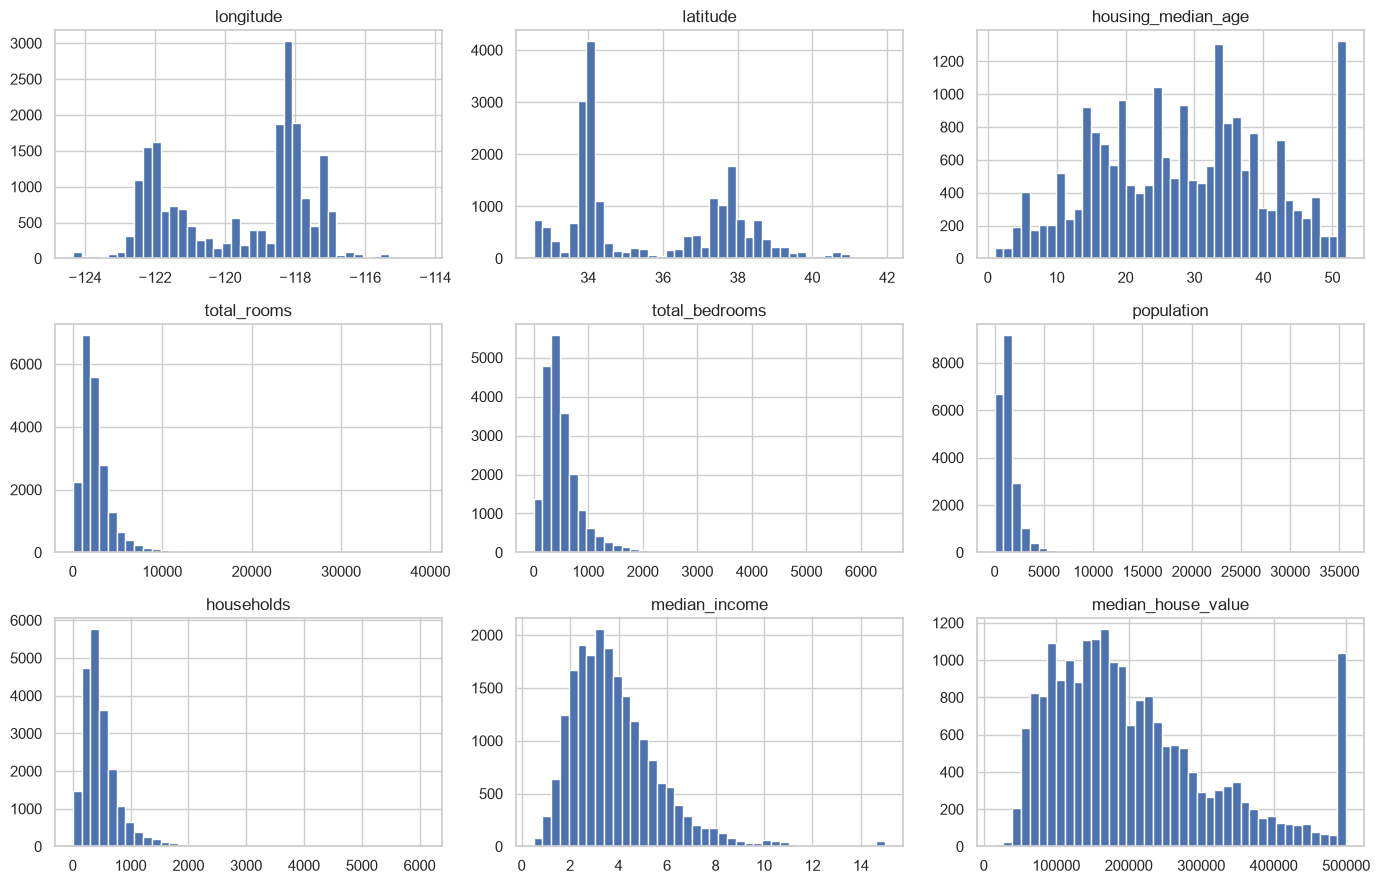

In [6]:
df.hist(bins=40, figsize=(14, 9))
plt.tight_layout()
plt.show()

> **Ojo:** `median_house_value` tiene un tope en 500.001 USD (los valores fueron recortados en el censo) y `total_bedrooms` tiene valores faltantes. Los datos reales tienen "trampas".

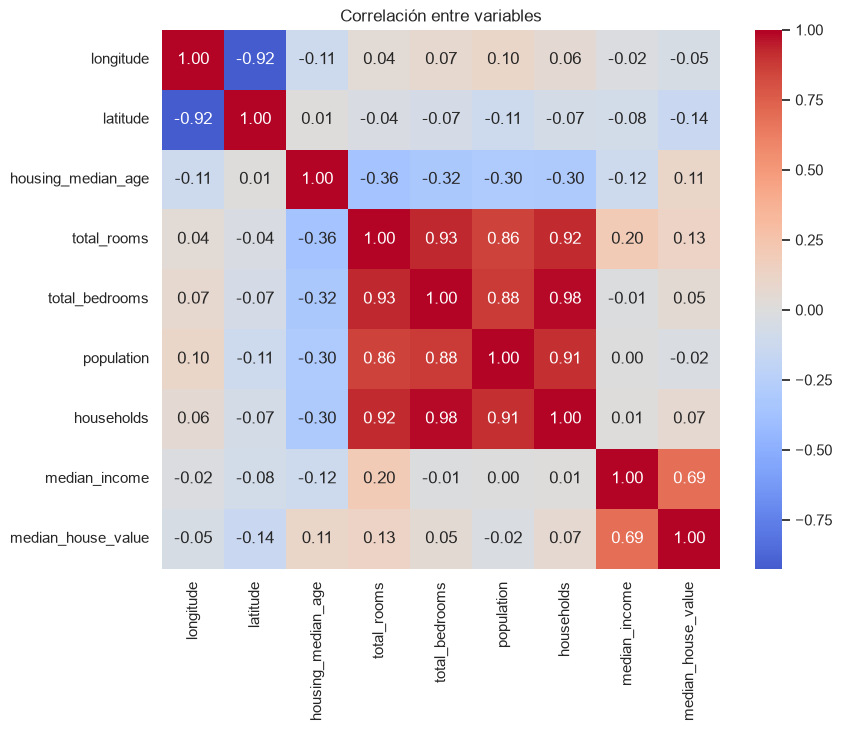

In [7]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre variables")
plt.show()

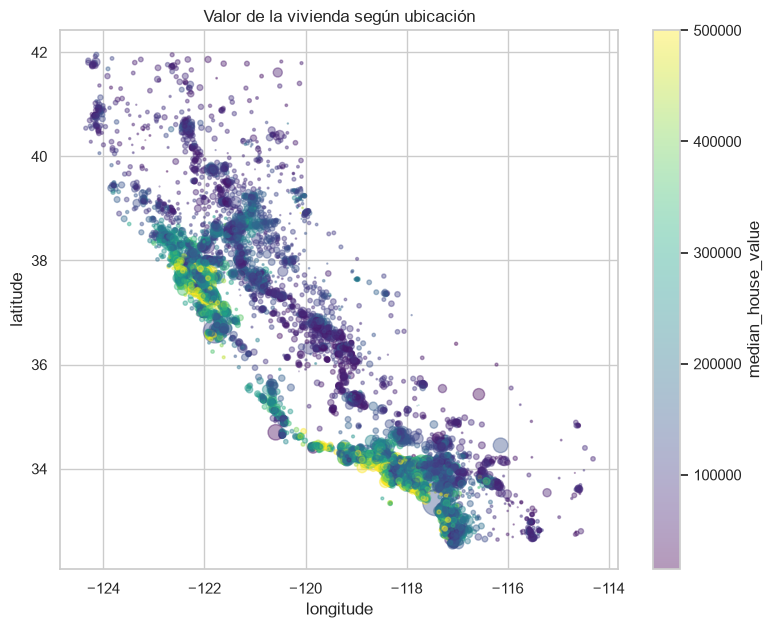

In [8]:
df.plot.scatter(x="longitude", y="latitude", c="median_house_value", cmap="viridis",
                s=df["population"] / 100, alpha=0.4, figsize=(9, 7))
plt.title("Valor de la vivienda según ubicación")
plt.show()

## 3. Separar en entrenamiento y prueba

El modelo **aprende** con `train` y lo **evaluamos** con `test`, datos que nunca vio.

In [9]:
X = df.drop(columns="median_house_value")
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}  Test: {X_test.shape}")

Train: (16512, 9)  Test: (4128, 9)


## 4. Preprocesamiento

- **Numéricas:** rellenar faltantes (`total_bedrooms`) con la mediana y estandarizar.
- **Categórica** (`ocean_proximity`): *one-hot encoding*.

Va dentro de un `Pipeline` para que se aprenda **solo con train** (evita *data leakage*).

In [10]:
numericas = X.select_dtypes("number").columns.tolist()
categoricas = ["ocean_proximity"]

preprocesamiento = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
])

## 5. Entrenar modelos

Comparamos un modelo simple (**regresión lineal**) con uno más flexible (**Random Forest**).

In [11]:
modelos = {
    "Regresión lineal": Pipeline([
        ("prep", preprocesamiento),
        ("modelo", LinearRegression()),
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocesamiento),
        ("modelo", RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
}

predicciones = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    predicciones[nombre] = modelo.predict(X_test)

## 6. Evaluar

- **MAE**: error absoluto promedio (en USD, las mismas unidades que `y`).
- **RMSE**: castiga más los errores grandes.
- **R²**: proporción de la varianza explicada (1 = perfecto, 0 = igual que predecir el promedio).

In [12]:
resultados = pd.DataFrame({
    nombre: {
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R²": r2_score(y_test, pred),
    }
    for nombre, pred in predicciones.items()
}).T.round(3)
resultados

,MAE,RMSE,R²
Regresión lineal,50752.606,69791.255,0.649
Random Forest,31974.055,49483.651,0.823


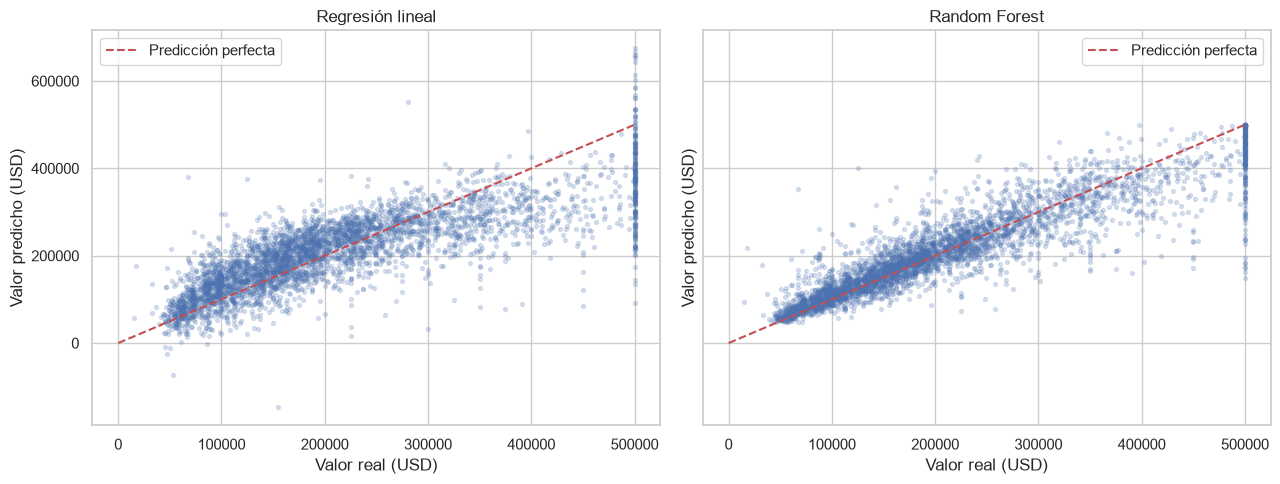

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (nombre, pred) in zip(axes, predicciones.items()):
    ax.scatter(y_test, pred, alpha=0.2, s=8)
    ax.plot([0, 500_000], [0, 500_000], "r--", label="Predicción perfecta")
    ax.set(title=nombre, xlabel="Valor real (USD)", ylabel="Valor predicho (USD)")
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Interpretar

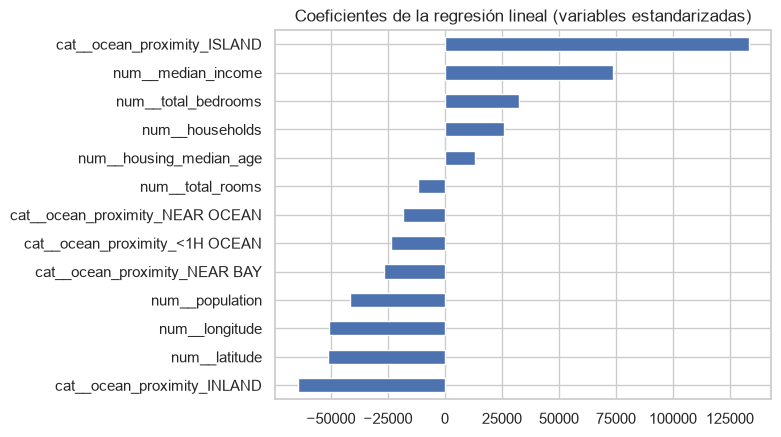

In [14]:
lineal = modelos["Regresión lineal"]
nombres = lineal.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lineal.named_steps["modelo"].coef_, index=nombres).sort_values()
coefs.plot.barh(title="Coeficientes de la regresión lineal (variables estandarizadas)")
plt.show()

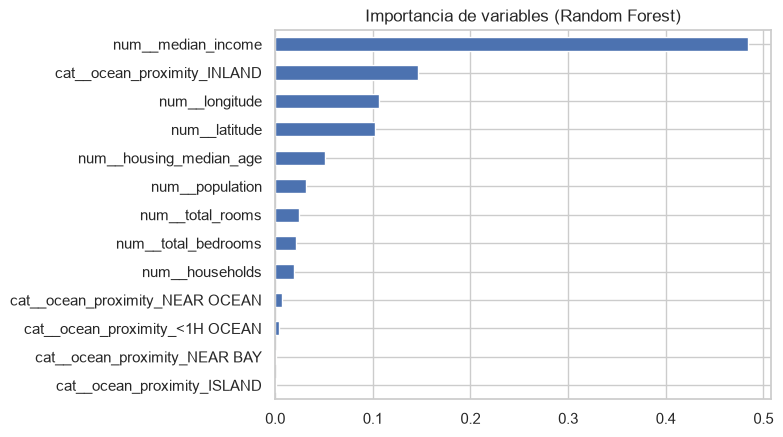

In [15]:
rf = modelos["Random Forest"]
importancias = pd.Series(rf.named_steps["modelo"].feature_importances_, index=nombres).sort_values()
importancias.plot.barh(title="Importancia de variables (Random Forest)")
plt.show()

## Conclusiones

- El ingreso del sector (`median_income`) es la variable más predictiva.
- Random Forest captura relaciones **no lineales** (por ejemplo, la ubicación) y logra un R² bastante mejor que la regresión lineal.
- La regresión lineal es más fácil de **explicar**: cada coeficiente dice cuánto sube o baja el precio.

## Ejercicios

1. Elimina `latitude`, `longitude` y `ocean_proximity` y vuelve a entrenar. ¿Cuánto empeora el R² de cada modelo?
2. Crea variables nuevas: `rooms_per_household = total_rooms / households` y `bedrooms_ratio = total_bedrooms / total_rooms`. ¿Mejora el modelo lineal?
3. Prueba distintos valores de `n_estimators` y `max_depth` en el Random Forest. ¿Ves overfitting? (Compara el R² en train y en test.)
4. Elimina las filas con `median_house_value >= 500_000` (el tope). ¿Cambian las métricas?